# 02 · Otsu threshold baseline on VH (task T12, experiment E0, run R00)

A baseline answers the question *"is a neural network worth it here?"* The simplest sensible flood mapper is one line: **water where VH is darker than a threshold**. Otsu's method picks that threshold automatically: it tries every possible cut of a histogram and keeps the one that makes the two resulting groups (dark and bright) as tight as possible. It uses no labels.

This notebook (1) decides how the threshold is chosen, (2) computes it on the training chips, (3) checks on training and validation data how far any single threshold could go, and (4) scores the baseline once on test and Bolivia with the same metric code that every U-Net will use.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import src  # noqa: F401  (must come before TensorFlow: switches on the XLA compile cache)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import data_stats, otsu_baseline, viz

viz.use_style()
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

## 1. One threshold for everything, or one per chip?

Otsu always splits a histogram in two, whether or not the image contains two kinds of surface. On a chip with no water it still returns a threshold, somewhere in the middle of the land values. The check below applies per-chip Otsu to the training chips that contain **no water at all** and measures how much of each chip it would call water.

In [2]:
false_alarm = otsu_baseline.per_chip_otsu_false_alarm("train")
print(f"training chips without water: {len(false_alarm)}")
print(f"share of the chip a per-chip Otsu threshold would call water: "
      f"median {np.median(false_alarm):.0%}, smallest {false_alarm.min():.0%}, largest {false_alarm.max():.0%}")

training chips without water: 32
share of the chip a per-chip Otsu threshold would call water: median 43%, smallest 15%, largest 67%


On chips with no water a per-chip threshold marks a large part of the land as water, every time. **Decision: one global threshold, computed from the VH values of all training chips.** It is also the more honest baseline: a rule fixed in advance and then applied to unseen images, which is exactly what the U-Nets have to do.

## 2. The threshold

In [3]:
threshold = otsu_baseline.train_threshold()
counts, centers = otsu_baseline.vh_histogram("train")
print(f"Otsu threshold on the VH values of the 252 training chips: {threshold:.2f} dB")
print(f"share of training VH pixels below it: {counts[centers < threshold].sum() / counts.sum():.1%}")

Otsu threshold on the VH values of the 252 training chips: -19.95 dB
share of training VH pixels below it: 19.1%


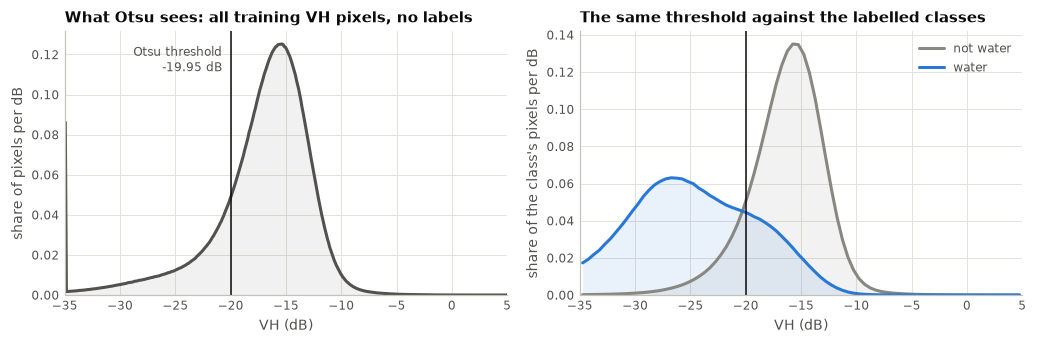

In [4]:
hist = pd.read_csv(ROOT / "results" / "db_histograms.csv")
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2))
axes[0].plot(centers, counts / counts.sum() / 0.1, color=viz.INK_2)
axes[0].fill_between(centers, counts / counts.sum() / 0.1, color=viz.INK_2, alpha=0.08, linewidth=0)
axes[0].axvline(threshold, color=viz.INK, linewidth=1)
axes[0].annotate(f"Otsu threshold\n{threshold:.2f} dB", (threshold, axes[0].get_ylim()[1] * 0.95), xytext=(-6, 0),
                 textcoords="offset points", ha="right", va="top", fontsize=8, color=viz.INK_2)
axes[0].set_title("What Otsu sees: all training VH pixels, no labels")
axes[0].set_xlabel("VH (dB)")
axes[0].set_ylabel("share of pixels per dB")
axes[0].set_xlim(-35, 5)
axes[0].set_ylim(bottom=0)

for cname, color, label in (("not_water", viz.GREY, "not water"), ("water", viz.BLUE, "water")):
    h = hist[(hist["band"] == "VH") & (hist["class"] == cname)]
    inside = h[np.isfinite(h["bin_left"]) & np.isfinite(h["bin_right"])]
    x = (inside["bin_left"] + inside["bin_right"]) / 2
    y = inside["count"] / h["count"].sum() / 0.5
    axes[1].plot(x, y, color=color, label=label)
    axes[1].fill_between(x, y, color=color, alpha=0.10, linewidth=0)
axes[1].axvline(threshold, color=viz.INK, linewidth=1)
axes[1].set_title("The same threshold against the labelled classes")
axes[1].set_xlabel("VH (dB)")
axes[1].set_ylabel("share of the class's pixels per dB")
axes[1].set_xlim(-35, 5)
axes[1].set_ylim(bottom=0)
axes[1].legend(loc="upper right")
fig.tight_layout()
viz.savefig(fig, ROOT / "figures" / "otsu_threshold.png")
plt.show()

The pooled histogram has one dominant hump (land) and a long dark shoulder (water). Otsu puts the cut at about −20 dB. Against the labels (right) the cut sits where the two class curves cross, so it is a reasonable threshold; but a good part of the water lies to its right (missed) and the dark tail of the land lies to its left (false alarms).

## 3. How far can *any* single VH threshold go? (training and validation only)

Purely as a diagnostic, the rule "water where VH < t" is scored for every t. This uses labels, so it is not the Otsu baseline; it shows the ceiling of thresholding as a method.

In [5]:
ts = np.arange(-30.0, -10.0 + 1e-9, 0.05)
sweep = pd.DataFrame({"threshold_db": ts,
                      "train_iou": otsu_baseline.threshold_sweep("train", ts),
                      "val_iou": otsu_baseline.threshold_sweep("val", ts)})
sweep.to_csv(ROOT / "results" / "R00_threshold_sweep.csv", index=False)

at_otsu = sweep.iloc[(sweep["threshold_db"] - threshold).abs().idxmin()]
best_train = sweep.loc[sweep["train_iou"].idxmax()]
ceiling = pd.DataFrame({
    "threshold (dB)": [threshold, best_train["threshold_db"]],
    "training IoU": [at_otsu["train_iou"], best_train["train_iou"]],
    "validation IoU": [at_otsu["val_iou"], best_train["val_iou"]],
}, index=["Otsu (no labels)", "best threshold on training labels"])
ceiling

,threshold (dB),training IoU,validation IoU
Otsu (no labels),-19.9500,0.3463,0.3880
best threshold on training labels,-23.6000,0.4653,0.4920


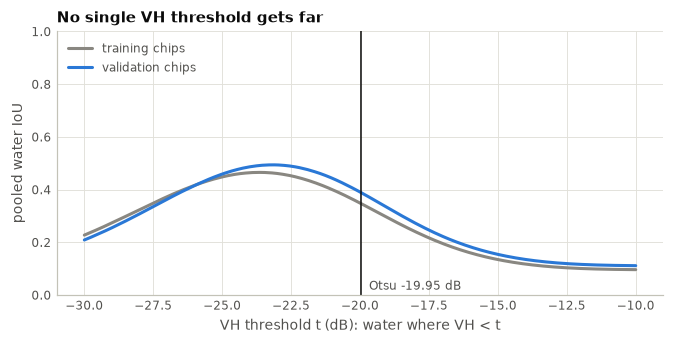

In [6]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.plot(sweep["threshold_db"], sweep["train_iou"], color=viz.GREY, label="training chips")
ax.plot(sweep["threshold_db"], sweep["val_iou"], color=viz.BLUE, label="validation chips")
ax.axvline(threshold, color=viz.INK, linewidth=1)
ax.annotate(f"Otsu {threshold:.2f} dB", (threshold, 0.02), xytext=(5, 0), textcoords="offset points", fontsize=8, color=viz.INK_2)
ax.set_xlabel("VH threshold t (dB): water where VH < t")
ax.set_ylabel("pooled water IoU")
ax.set_ylim(0, 1)
ax.set_title("No single VH threshold gets far")
ax.legend(loc="upper left")
fig.tight_layout()
viz.savefig(fig, ROOT / "figures" / "otsu_threshold_sweep.png")
plt.show()

Even the best threshold that could be picked with the training labels gains only a little over Otsu, and both stay far from a perfect score. The limit is the method (one number per pixel, no context), not the choice of threshold. Otsu is kept as the baseline, exactly as planned; the label-tuned threshold is **not** scored on test.

## 4. Score the baseline (run R00)

The threshold is now fixed. The rule is scored on validation (for later comparisons that must not touch test), and **once** on test and on Bolivia.

In [7]:
metrics = otsu_baseline.main()

Otsu threshold on the training VH pixels: -19.95 dB


val      IoU 0.3880  P 0.4265  R 0.8110  F1 0.5591  mean per-chip IoU 0.2642 (86 chips, 3 skipped)


test     IoU 0.4334  P 0.4827  R 0.8094  F1 0.6047  mean per-chip IoU 0.2604 (89 chips, 1 skipped)


bolivia  IoU 0.6529  P 0.7310  R 0.8594  F1 0.7900  mean per-chip IoU 0.4423 (15 chips, 0 skipped)
wrote /mnt/d/Projects/College Project/FloodWatch/floodwatch/results/R00


In [8]:
rows = {}
for split in ("val", "test", "bolivia"):
    m = metrics[split]
    rows[split] = {"chips": m["n_chips"], "water IoU (pooled)": m["iou"], "precision": m["precision"], "recall": m["recall"],
                   "F1": m["f1"], "mean per-chip IoU": m["mean_chip_iou"], "chips in the mean": m["chips_in_mean"],
                   "IoU without no-radar pixels": m["observed_only"]["iou"]}
pd.DataFrame(rows).T

,chips,water IoU (pooled),precision,recall,F1,mean per-chip IoU,chips in the mean,IoU without no-radar pixels
val,89.0000,0.3880,0.4265,0.8110,0.5591,0.2642,86.0000,0.3885
test,90.0000,0.4334,0.4827,0.8094,0.6047,0.2604,89.0000,0.4381
bolivia,15.0000,0.6529,0.7310,0.8594,0.7900,0.4423,15.0000,0.6562


**Reading the baseline.**

* On the test split the threshold finds most of the water (high recall) but about half of what it flags is not water (low precision): dark land is the weak point of thresholding.
* The mean per-chip IoU is much lower than the pooled IoU. The pooled number is carried by a few chips with a lot of open water; on the many chips with little water, a handful of false alarms is enough to ruin the chip's score.
* Bolivia scores higher than test. This is not "generalisation": a fixed threshold has nothing to generalise. The Bolivia chips simply contain large, open water bodies that are easy to threshold.

These are the numbers a U-Net has to beat. They are stored in `results/R00/` in the same format as every later run.